# 04 — Report figures

**Lights Out: Predicting Storm-Driven Power Outages and Recovery Across U.S. Counties**

This notebook redraws **every figure of the report** into `figures/`, with one common style. It trains nothing:

- the exploration figures (Part II) are computed directly from `data/`, with the same code as `01_eda.ipynb`;
- the classifier and regression figures (Part IV) are read from the results that `02_classifier.ipynb` and
  `03_regression.ipynb` saved in `results/`.

Run `02_classifier.ipynb` and `03_regression.ipynb` once first if `results/` is empty. Running this notebook takes a few seconds.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay

DATA = Path('..') / 'data'
RES = Path('..') / 'results'
FIG = Path('..') / 'figures'
FIG.mkdir(exist_ok=True)
plt.rcParams.update({'figure.figsize': (9, 4), 'figure.dpi': 100, 'axes.spines.top': False, 'axes.spines.right': False})

saved = []
def save(fig, name):
    fig.savefig(FIG / name, dpi=150, bbox_inches='tight')
    saved.append(name)
    plt.show()

## Part II: exploration figures

In [2]:
storms = pd.read_csv(DATA / 'storms.csv')
utility = pd.read_csv(DATA / 'utility_by_county.csv', low_memory=False)
storms['date'] = pd.to_datetime(storms['landfall'].fillna(storms['first_impact_date']), errors='coerce')
storms['year'] = storms['date'].dt.year
df = utility.merge(storms[['event_id', 'name', 'kind', 'year']], on='event_id', how='left')
df['major_outage'] = (df['peak_share_out'] > 0.10).where(df['peak_share_out'].notna())
share = df['peak_share_out'].dropna()
hours = df['hours_to_90pct_restored'].dropna()

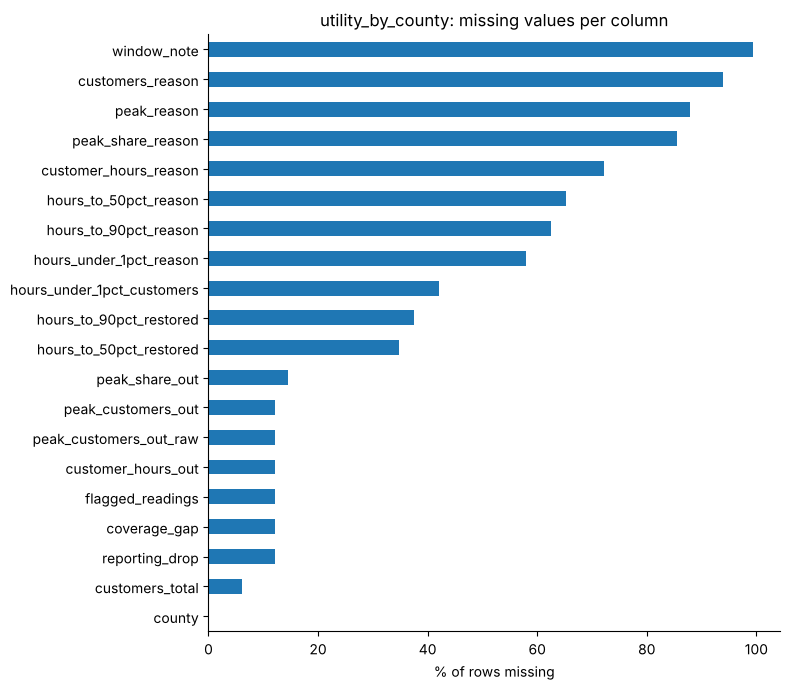

In [3]:
missing = utility.isna().mean().sort_values(ascending=False)
missing = missing[missing > 0]
fig, ax = plt.subplots(figsize=(8, 7))
(missing * 100).plot.barh(ax=ax)
ax.set_xlabel('% of rows missing'); ax.set_title('utility_by_county: missing values per column'); ax.invert_yaxis()
plt.tight_layout(); save(fig, 'missing_values.png')

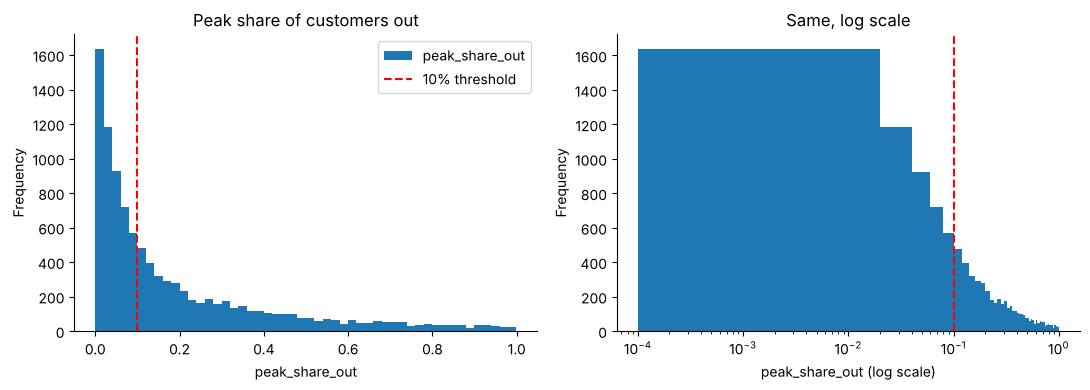

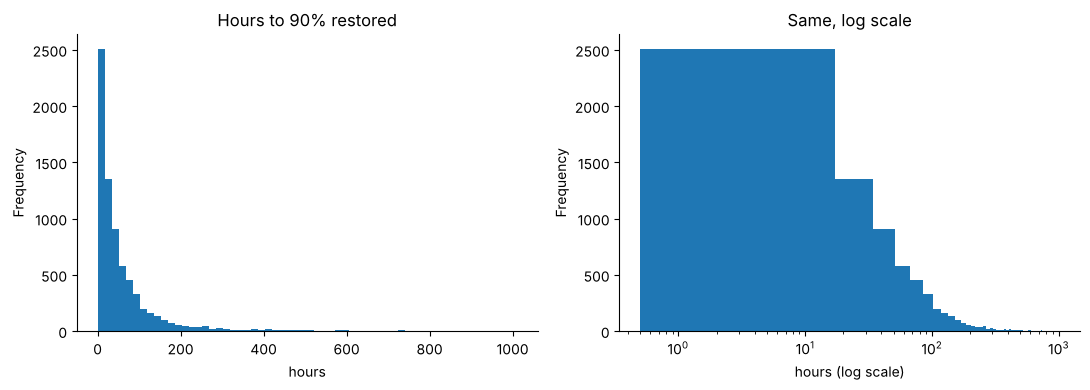

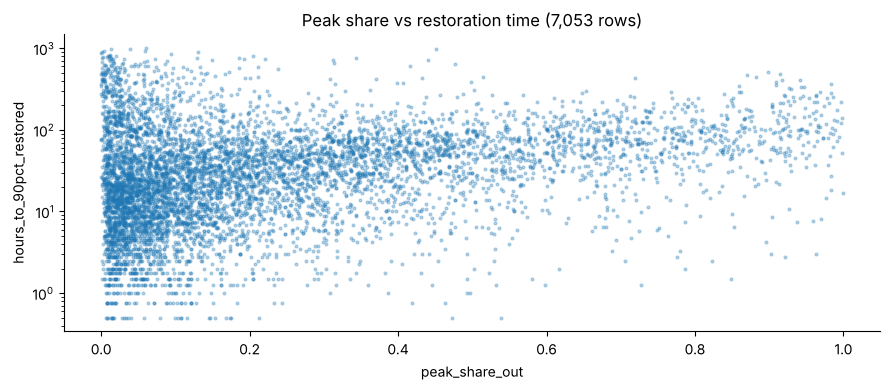

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
share.plot.hist(bins=50, ax=axes[0])
axes[0].axvline(0.10, color='red', ls='--', label='10% threshold')
axes[0].set_xlabel('peak_share_out'); axes[0].set_title('Peak share of customers out'); axes[0].legend()
share.clip(lower=1e-4).plot.hist(bins=50, ax=axes[1], logx=True)
axes[1].set_xscale('log'); axes[1].axvline(0.10, color='red', ls='--')
axes[1].set_xlabel('peak_share_out (log scale)'); axes[1].set_title('Same, log scale')
plt.tight_layout(); save(fig, 'peak_share_out.png')

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
hours.plot.hist(bins=60, ax=axes[0])
axes[0].set_xlabel('hours'); axes[0].set_title('Hours to 90% restored')
hours.clip(lower=0.25).plot.hist(bins=60, ax=axes[1])
axes[1].set_xscale('log'); axes[1].set_xlabel('hours (log scale)'); axes[1].set_title('Same, log scale')
plt.tight_layout(); save(fig, 'hours_to_90pct.png')

both = df.dropna(subset=['peak_share_out', 'hours_to_90pct_restored'])
fig, ax = plt.subplots(figsize=(9, 4))
both.plot.scatter(x='peak_share_out', y='hours_to_90pct_restored', s=4, alpha=0.3, logy=True, ax=ax)
ax.set_title(f'Peak share vs restoration time ({len(both):,} rows)')
plt.tight_layout(); save(fig, 'share_vs_hours.png')

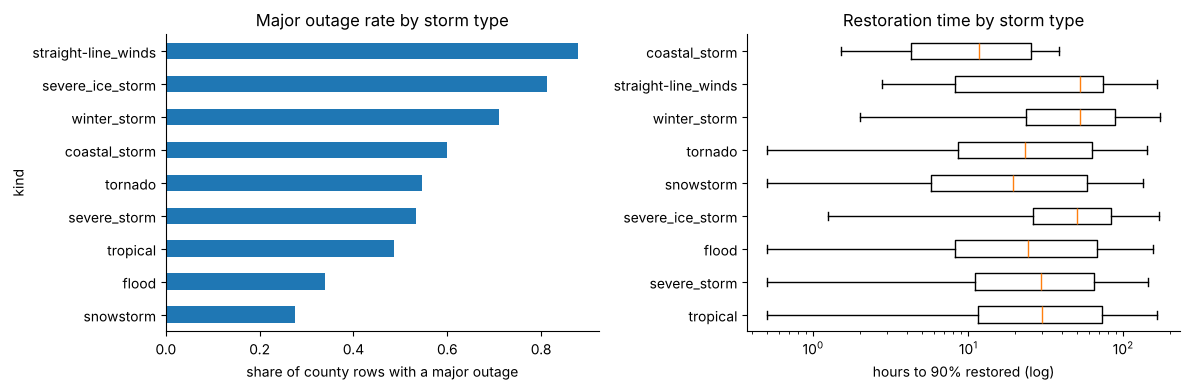

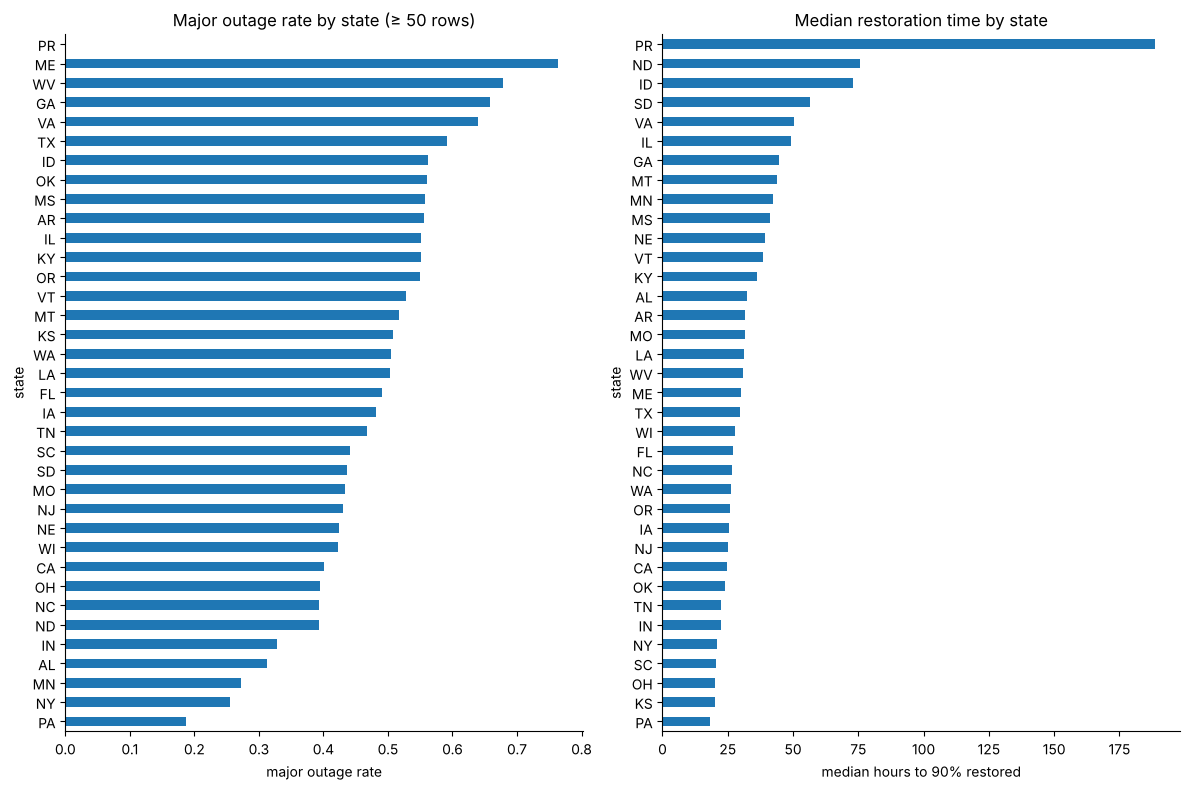

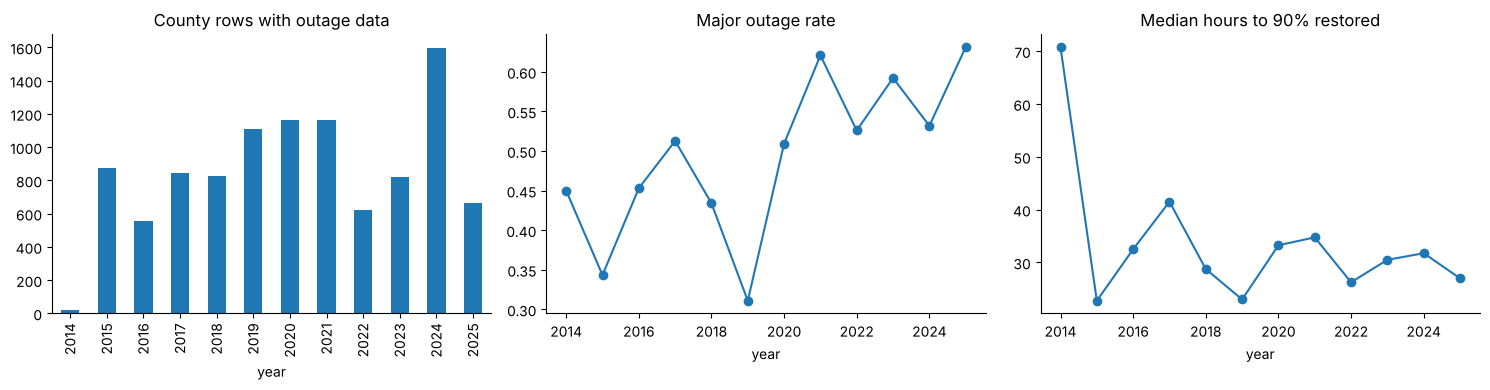

In [5]:
by_kind = df.groupby('kind').agg(county_rows=('event_id', 'size'), major_rate=('major_outage', 'mean'),
                                 median_hours_90=('hours_to_90pct_restored', 'median')
                                 ).sort_values('county_rows', ascending=False)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
by_kind['major_rate'].sort_values().plot.barh(ax=axes[0])
axes[0].set_xlabel('share of county rows with a major outage'); axes[0].set_title('Major outage rate by storm type')
order = by_kind.index.tolist()
data = [df.loc[df['kind'] == k, 'hours_to_90pct_restored'].dropna() for k in order]
axes[1].boxplot(data, orientation='horizontal', showfliers=False)
axes[1].set_yticks(range(1, len(order) + 1), order)
axes[1].set_xscale('log'); axes[1].set_xlabel('hours to 90% restored (log)'); axes[1].set_title('Restoration time by storm type')
plt.tight_layout(); save(fig, 'by_storm_type.png')

by_state = df.groupby('state').agg(county_rows=('event_id', 'size'), major_rate=('major_outage', 'mean'),
                                   median_hours_90=('hours_to_90pct_restored', 'median'))
by_state = by_state[by_state['county_rows'] >= 50]
fig, axes = plt.subplots(1, 2, figsize=(12, 8))
by_state['major_rate'].sort_values().plot.barh(ax=axes[0])
axes[0].set_xlabel('major outage rate'); axes[0].set_title('Major outage rate by state (≥ 50 rows)')
by_state['median_hours_90'].sort_values().plot.barh(ax=axes[1])
axes[1].set_xlabel('median hours to 90% restored'); axes[1].set_title('Median restoration time by state')
plt.tight_layout(); save(fig, 'by_state.png')

by_year = df.groupby('year').agg(usable_rows=('reason', lambda r: (r == 'ok').sum()), major_rate=('major_outage', 'mean'),
                                 median_hours_90=('hours_to_90pct_restored', 'median'))
by_year.index = by_year.index.astype(int)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
by_year['usable_rows'].plot.bar(ax=axes[0]); axes[0].set_title('County rows with outage data')
by_year['major_rate'].plot(marker='o', ax=axes[1]); axes[1].set_title('Major outage rate')
by_year['median_hours_90'].plot(marker='o', ax=axes[2]); axes[2].set_title('Median hours to 90% restored')
for a in axes: a.set_xlabel('year')
plt.tight_layout(); save(fig, 'by_year.png')

## Part IV: classifier figures (from `results/`)

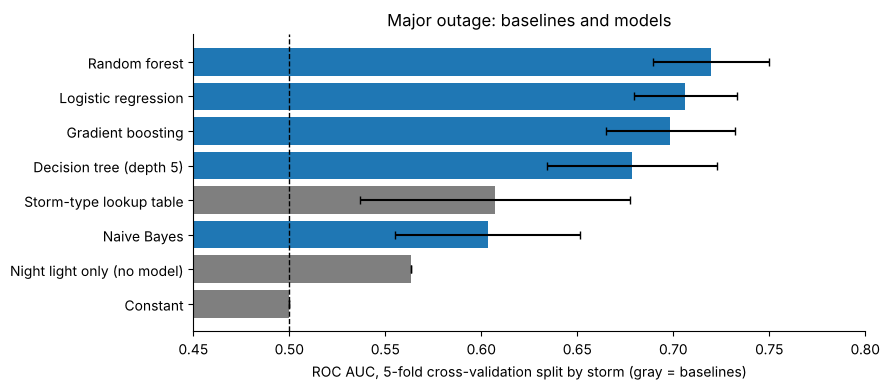

In [6]:
summary = pd.read_csv(RES / 'classifier_cv_summary.csv', index_col='model')
preds = pd.read_csv(RES / 'classifier_test_predictions.csv')
per_storm = pd.read_csv(RES / 'classifier_per_storm.csv')
final = json.loads((RES / 'classifier_final_model.json').read_text())
BASELINES = ['Constant', 'Night light only (no model)', 'Storm-type lookup table']

fig, ax = plt.subplots(figsize=(9, 4))
colors = ['tab:gray' if k in BASELINES else 'tab:blue' for k in summary.index]
ax.barh(summary.index, summary['mean AUC'], xerr=summary['std'], color=colors, capsize=3)
ax.axvline(0.5, color='black', ls='--', lw=1)
ax.set_xlim(0.45, 0.8)
ax.set_xlabel('ROC AUC, 5-fold cross-validation split by storm (gray = baselines)')
ax.set_title('Major outage: baselines and models')
plt.tight_layout(); save(fig, 'classifier_models.png')

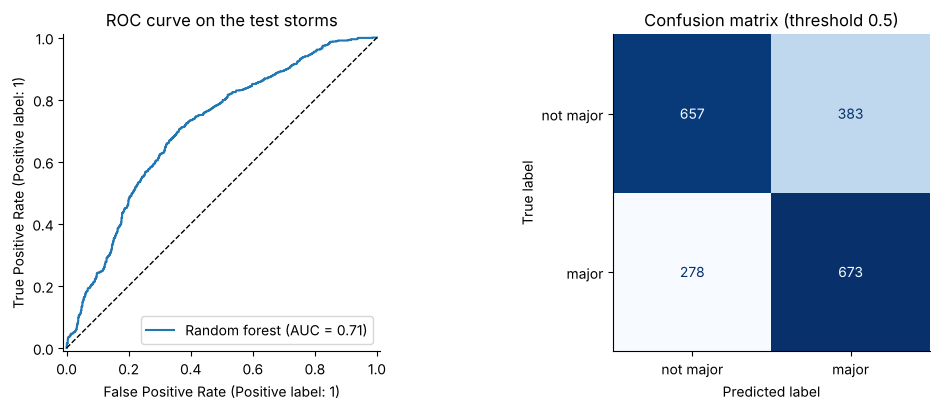

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
RocCurveDisplay.from_predictions(preds['major_outage'], preds['proba'], ax=axes[0], name=final['model'])
axes[0].plot([0, 1], [0, 1], 'k--', lw=1)
axes[0].set_title('ROC curve on the test storms')
ConfusionMatrixDisplay.from_predictions(preds['major_outage'], preds['pred'], display_labels=['not major', 'major'],
                                        ax=axes[1], colorbar=False, cmap='Blues')
axes[1].set_title('Confusion matrix (threshold 0.5)')
plt.tight_layout(); save(fig, 'classifier_test.png')

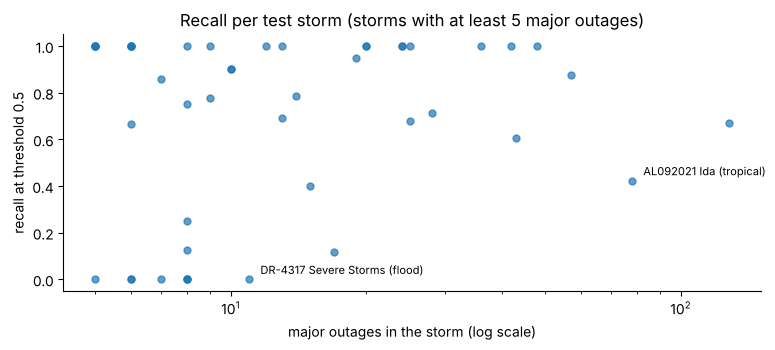

In [8]:
big = per_storm[per_storm['major'] >= 5]
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.scatter(big['major'], big['recall'], s=25, alpha=0.7)
worst = big.sort_values(['recall', 'major'], ascending=[True, False]).iloc[0]
most_missed = big.assign(missed=big['major'] - big['found']).sort_values('missed').iloc[-1]
for s in (worst, most_missed):
    ax.annotate(f"{s['event_id']} {s['name'].split(',')[0][:20]} ({s['kind']})", (s['major'], s['recall']),
                xytext=(8, 4), textcoords='offset points', fontsize=8)
ax.set_xscale('log')
ax.set_xlabel('major outages in the storm (log scale)')
ax.set_ylabel('recall at threshold 0.5')
ax.set_title('Recall per test storm (storms with at least 5 major outages)')
plt.tight_layout(); save(fig, 'classifier_recall_per_storm.png')

## Part IV: regression figures (from `results/`)

These come from `03_regression.ipynb`, which saved its numbers in `results/regression_*`.

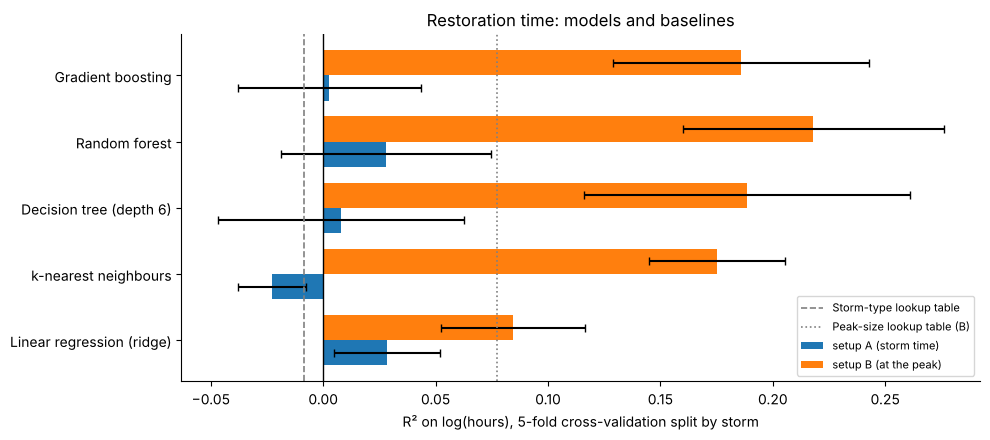

In [9]:
reg_cv = pd.read_csv(RES / 'regression_cv_summary.csv')
reg_pred = pd.read_csv(RES / 'regression_test_predictions.csv')
reg_err = pd.read_csv(RES / 'regression_errors_by_kind.csv', index_col='kind')
reg_final = json.loads((RES / 'regression_summary.json').read_text())['final_models']
MODELS = ['Linear regression (ridge)', 'k-nearest neighbours', 'Decision tree (depth 6)', 'Random forest', 'Gradient boosting']

fig, ax = plt.subplots(figsize=(10, 4.5))
pos = np.arange(len(MODELS))
for k, (setup, color) in enumerate([('A', 'tab:blue'), ('B', 'tab:orange')]):
    t = reg_cv[reg_cv['setup'] == setup].set_index('model').loc[MODELS]
    ax.barh(pos + (k - 0.5) * 0.38, t['R2'], height=0.38, xerr=t['R2 std'], color=color, capsize=3,
            label=f'setup {setup}' + (' (storm time)' if setup == 'A' else ' (at the peak)'))
base = reg_cv.set_index('model')['R2']
for name, ls in [('Storm-type lookup table', '--'), ('Peak-size lookup table (B)', ':')]:
    ax.axvline(base[name], color='gray', ls=ls, lw=1.2, label=name)
ax.axvline(0, color='black', lw=1)
ax.set_yticks(pos, MODELS)
ax.set_xlabel('R² on log(hours), 5-fold cross-validation split by storm')
ax.set_title('Restoration time: models and baselines')
ax.legend(loc='lower right', fontsize=8)
plt.tight_layout(); save(fig, 'regression_models.png')

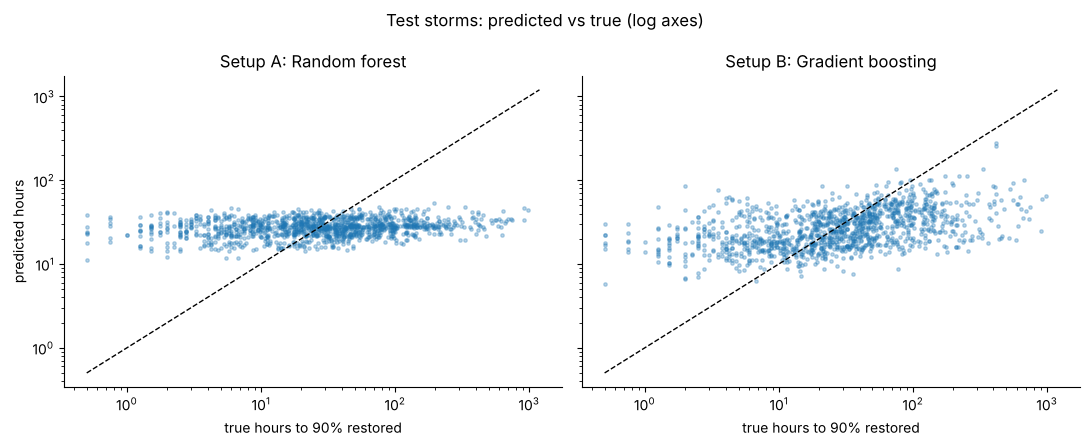

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)
for ax, setup in zip(axes, ['A', 'B']):
    ax.scatter(reg_pred['hours_to_90pct_restored'], reg_pred[f'pred_hours_{setup}'], s=6, alpha=0.3)
    ax.plot([0.5, 1200], [0.5, 1200], 'k--', lw=1)
    ax.set_xscale('log'); ax.set_yscale('log')
    ax.set_xlabel('true hours to 90% restored')
    ax.set_title(f"Setup {setup}: {reg_final[setup]['model']}")
axes[0].set_ylabel('predicted hours')
plt.suptitle('Test storms: predicted vs true (log axes)')
plt.tight_layout(); save(fig, 'regression_test.png')

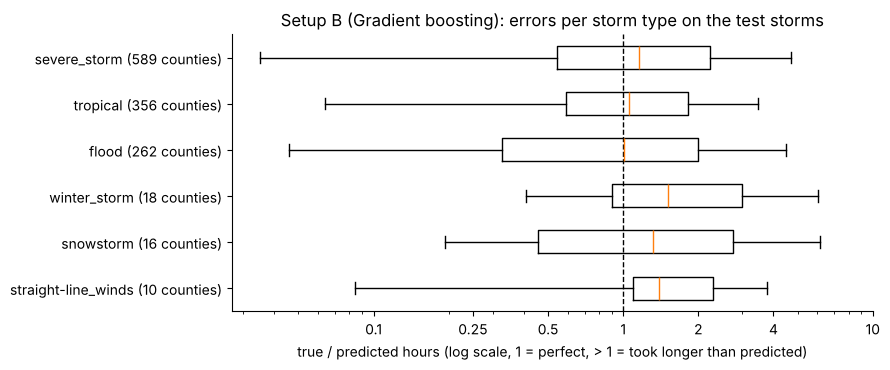

In [11]:
resid = reg_pred['log_hours'] - reg_pred['pred_log_B']
kinds = reg_err[reg_err['rows'] >= 10].index.tolist()[::-1]
ratios = [np.exp(resid[reg_pred['kind'] == k]) for k in kinds]
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.boxplot(ratios, orientation='horizontal', showfliers=False)
ax.set_yticks(range(1, len(kinds) + 1), [f"{k} ({reg_err.loc[k, 'rows']} counties)" for k in kinds])
ax.axvline(1, color='black', ls='--', lw=1)
ax.set_xscale('log')
ax.set_xticks([0.1, 0.25, 0.5, 1, 2, 4, 10], ['0.1', '0.25', '0.5', '1', '2', '4', '10'])
ax.set_xlabel('true / predicted hours (log scale, 1 = perfect, > 1 = took longer than predicted)')
ax.set_title(f"Setup B ({reg_final['B']['model']}): errors per storm type on the test storms")
plt.tight_layout(); save(fig, 'regression_errors_by_kind.png')

## Part IV: case study, Hurricane Ida (2021)

Ida is a test storm: the classifier never saw it during training. This map compares the real major outages with
the test predictions saved in `results/classifier_test_predictions.csv`, county by county. County shapes come from
`figures/ida_counties.geojson` (U.S. Census Bureau cartographic boundaries, public domain).

In [ ]:
from matplotlib.patches import Polygon, Patch
from matplotlib.collections import PatchCollection

ida = preds[preds['event_id'] == 'AL092021'].copy()
ida['geoid'] = ida['geoid'].astype(str).str.zfill(5)
radius = pd.read_csv(DATA / 'county_summary.csv', usecols=['event_id', 'geoid', 'in_nhc_wind_radius'], low_memory=False)
radius = radius[radius['event_id'] == 'AL092021']
ida = ida.merge(radius.assign(geoid=radius['geoid'].astype(str).str.zfill(5))[['geoid', 'in_nhc_wind_radius']], on='geoid', how='left')
ida = ida.set_index('geoid')
print(pd.crosstab([ida['in_nhc_wind_radius'], ida['major_outage']], ida['pred'], margins=True))

shapes = json.loads((FIG / 'ida_counties.geojson').read_text())['features']
def rings(geom):
    polys = geom['coordinates'] if geom['type'] == 'MultiPolygon' else [geom['coordinates']]
    return [np.array(p[0]) for p in polys]

GREY, RED, BLUE, ORANGE = '#e6e6e6', '#c0392b', '#2e86c1', '#f0b27a'
def colour(row, panel):
    if row is None:
        return 'white'
    if panel == 'real':
        return RED if row['major_outage'] == 1 else GREY
    if row['pred'] == 1:
        return RED if row['major_outage'] == 1 else ORANGE
    return BLUE if row['major_outage'] == 1 else GREY

regions = {'Louisiana and Mississippi (landfall)': (-94.2, -88.0, 28.9, 35.1),
           'Pennsylvania, New Jersey, New York (remnants)': (-78.6, -72.6, 38.8, 42.3)}
fig, axes = plt.subplots(2, 2, figsize=(11, 9.5))
for r, (title, (x0, x1, y0, y1)) in enumerate(regions.items()):
    for c, panel in enumerate(['real', 'model']):
        ax = axes[r, c]
        patches, faces, edges, widths = [], [], [], []
        for f in shapes:
            row = ida.loc[f['id']] if f['id'] in ida.index else None
            inside = row is not None and row['in_nhc_wind_radius'] == True
            for ring in rings(f['geometry']):
                patches.append(Polygon(ring, closed=True))
                faces.append(colour(row, panel))
                edges.append('black' if inside else '#9a9a9a')
                widths.append(1.1 if inside else 0.3)
        ax.add_collection(PatchCollection(patches, facecolor=faces, edgecolor=edges, linewidth=widths))
        ax.set_xlim(x0, x1); ax.set_ylim(y0, y1); ax.set_aspect(1 / np.cos(np.radians((y0 + y1) / 2)))
        ax.set_xticks([]); ax.set_yticks([])
        for s in ax.spines.values():
            s.set_visible(False)
        ax.set_title(('Real outages' if panel == 'real' else 'Model prediction (threshold 0.5)') + f'\n{title}', fontsize=10)
legend = [Patch(facecolor=RED, label='Major outage (real) / found by the model'),
          Patch(facecolor=BLUE, label='Major outage missed by the model'),
          Patch(facecolor=ORANGE, label='False alarm'),
          Patch(facecolor=GREY, label='No major outage'),
          Patch(facecolor='white', edgecolor='#9a9a9a', label='No outage record (not scored)'),
          Patch(facecolor='none', edgecolor='black', linewidth=1.5, label='Inside the NHC 34-knot wind radius')]
fig.legend(handles=legend, loc='lower center', ncol=3, frameon=False, fontsize=9)
fig.suptitle('Hurricane Ida (2021), a test storm: real major outages vs the classifier', fontsize=12)
fig.tight_layout(rect=(0, 0.06, 1, 0.97))
save(fig, 'ida_case_study_map.png')

In [12]:
used = sorted(p.name for p in FIG.glob('*.png'))
print(f'{len(saved)} figures redrawn:', ', '.join(saved))
print('figures in figures/ not redrawn here:', [p for p in used if p not in saved] or 'none')

13 figures redrawn: missing_values.png, peak_share_out.png, hours_to_90pct.png, share_vs_hours.png, by_storm_type.png, by_state.png, by_year.png, classifier_models.png, classifier_test.png, classifier_recall_per_storm.png, regression_models.png, regression_test.png, regression_errors_by_kind.png
figures in figures/ not redrawn here: none
